# COVID-19 Clinical Outcome Prediction — Model Evaluation Lab

**Purpose:** extend the existing clinical-only baseline with leakage-aware preprocessing, three outcome tasks, classical model comparisons, cross-validation on the training split, threshold-independent metrics, and reproducible plots.

> **Scope warning:** this notebook evaluates clinical variables from the available CSV. It does **not** reproduce or validate the paper's CT-radiomics models. It is an exploratory academic experiment, not a clinical decision tool.

## Before running
1. Put the CSV beside this notebook, or update `DATA_PATH`.
2. Run cells from top to bottom.
3. Review the feature-timing audit carefully. Features must be available at the intended prediction time. This CSV may contain records collected after outcomes; this notebook cannot prove every feature is admission-time data.

## 1. Imports and configuration

This notebook keeps the test set untouched during model selection. Imputation and one-hot encoding happen inside scikit-learn pipelines, so they are fitted on training folds only.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report, brier_score_loss
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
DATA_PATH = "deidentified_overlap_tcia.csv.cleaned.csv_20210806.csv"
OUTPUT_DIR = "evaluation_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

print("Output directory:", os.path.abspath(OUTPUT_DIR))

Output directory: /home/prathik/Documents/ML/evaluation_outputs


## 2. Load and inspect the dataset

In [4]:
df = pd.read_csv(DATA_PATH, low_memory=False)
required = {"to_patient_id", "is_icu", "was_ventilated", "last.status"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {sorted(missing_required)}")

print(f"Rows: {len(df):,}")
print(f"Unique non-missing patient IDs: {df['to_patient_id'].nunique():,}")
print(f"Columns: {len(df.columns):,}")
display(df.head())

Rows: 1,384
Unique non-missing patient IDs: 1,384
Columns: 131


,to_patient_id,covid19_statuses,last.status,age.splits,gender_concept_name,visit_start_datetime,visit_concept_name,is_icu,was_ventilated,invasive_vent_days,...,33254-4_pH of Arterial blood adjusted to patient's actual temperature,30341-2_Erythrocyte sedimentation rate,2345-7_Glucose [Mass/volume] in Serum or Plasma,13457-7_Cholesterol in LDL [Mass/volume] in Serum or Plasma by calculation,13458-5_Cholesterol in VLDL [Mass/volume] in Serum or Plasma by calculation,2571-8_Triglyceride [Mass/volume] in Serum or Plasma,2085-9_Cholesterol in HDL [Mass/volume] in Serum or Plasma,therapeutic.exnox.Boolean,therapeutic.heparin.Boolean,Other.anticoagulation.therapy
0,A917122,positive,discharged,"(74,90]",FEMALE,1/1/1901,Inpatient Visit,False,No,NaN,...,NaN,39.0,128.0,NaN,NaN,NaN,NaN,False,True,apixaban
1,A387558,positive,deceased,"(74,90]",MALE,1/1/1901,Inpatient Visit,True,No,NaN,...,7.39,NaN,199.0,NaN,NaN,NaN,NaN,True,True,apixaban
2,A968238,positive,deceased,"(74,90]",MALE,1/5/1901,Inpatient Visit,True,Yes,28.0,...,7.45,54.0,134.0,NaN,NaN,NaN,NaN,False,True,not documented
3,A106133,positive,deceased,"(74,90]",FEMALE,1/1/1901,Inpatient Visit,False,No,NaN,...,NaN,NaN,265.0,63.0,31.0,153.0,36.0,True,True,not documented
4,A300871,positive,deceased,"(74,90]",FEMALE,1/1/1901,Inpatient Visit,False,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,not documented


## 3. Define outcomes

ICU and ventilation are mapped from common yes/no encodings. Death is mapped from `last.status`; unknown statuses remain missing and are excluded only from that outcome's task.

For patients with multiple rows, this notebook defines each outcome as **ever recorded positive across their rows**. This is a retrospective label definition, not proof that predictors precede the outcome.

In [5]:
def convert_binary(series):
    mapping = {
        "true": 1, "yes": 1, "1": 1, "y": 1,
        "false": 0, "no": 0, "0": 0, "n": 0
    }
    return series.astype("string").str.strip().str.lower().map(mapping)

targets = pd.DataFrame(index=df.index)
targets["ICU"] = convert_binary(df["is_icu"])
targets["Ventilation"] = convert_binary(df["was_ventilated"])
status = df["last.status"].astype("string").str.strip().str.lower()
targets["Death"] = status.map({"deceased": 1, "discharged": 0})

for target in targets:
    print(f"\n{target} label counts (including missing):")
    display(targets[target].value_counts(dropna=False).rename_axis("label").to_frame("rows"))


ICU label counts (including missing):


,rows
label,
0,1124
1,260



Ventilation label counts (including missing):


,rows
label,
0,1171
1,213



Death label counts (including missing):


,rows
label,
0,1201
1,183


## 4. Select candidate predictors and audit timing

The list below preserves the clinical features used in the earlier baseline. IDs and outcome fields are never predictors. **Important:** a field can still leak information even if it is not literally an outcome column—for example, measurements taken after ICU admission or ventilation. Inspect your dataset documentation and remove any feature that would not be known at prediction time.

The `days_prior_sx` field is included as a candidate, but its interpretation should be confirmed. Deidentified dates and patient identifiers are not used.

In [6]:
candidate_features = [
    "age.splits", "gender_concept_name", "days_prior_sx", "smoking_status_v",
    "cough_v", "dyspnea_admission_v", "nausea_v", "vomiting_v", "diarrhea_v",
    "abdominal_pain_v", "fever_v",
    "htn_v", "dm_v", "cad_v", "hf_ef_v", "ckd_v", "malignancies_v",
    "copd_v", "other_lung_disease_v",
    "BMI.over30", "BMI.over35", "temperature.over38", "pulseOx.under90",
    "Respiration.over24", "HeartRate.over100",
    "8331-1_Oral temperature",
    "59408-5_Oxygen saturation in Arterial blood by Pulse oximetry",
    "9279-1_Respiratory rate",
    "76282-3_Heart rate.beat-to-beat by EKG",
    "8480-6_Systolic blood pressure",
    "33256-9_Leukocytes [#/volume] corrected for nucleated erythrocytes in Blood by Automated count",
    "751-8_Neutrophils [#/volume] in Blood by Automated count",
    "731-0_Lymphocytes [#/volume] in Blood by Automated count",
    "2951-2_Sodium [Moles/volume] in Serum or Plasma",
    "1920-8_Aspartate aminotransferase [Enzymatic activity/volume] in Serum or Plasma",
    "2160-0_Creatinine [Mass/volume] in Serum or Plasma",
    "39156-9_Body mass index (BMI) [Ratio]"
]
feature_cols = [c for c in candidate_features if c in df.columns]
not_found = [c for c in candidate_features if c not in df.columns]
if not feature_cols:
    raise ValueError("None of the candidate feature columns were found in the CSV.")

print(f"Found {len(feature_cols)} of {len(candidate_features)} candidate features.")
if not_found:
    print("Candidate columns not present (ignored):", not_found)

feature_audit = pd.DataFrame({
    "feature": feature_cols,
    "dtype": [str(df[c].dtype) for c in feature_cols],
    "missing_pct": [100 * df[c].isna().mean() for c in feature_cols],
    "unique_nonmissing": [df[c].nunique(dropna=True) for c in feature_cols],
})
display(feature_audit.sort_values("missing_pct", ascending=False).round(1))
feature_audit.to_csv(os.path.join(OUTPUT_DIR, "feature_audit.csv"), index=False)

Found 36 of 37 candidate features.
Candidate columns not present (ignored): ['39156-9_Body mass index (BMI) [Ratio]']


,feature,dtype,missing_pct,unique_nonmissing
20,BMI.over35,object,31.2,2
19,BMI.over30,object,31.2,2
32,731-0_Lymphocytes [#/volume] in Blood by Autom...,float64,29.4,232
31,751-8_Neutrophils [#/volume] in Blood by Autom...,float64,29.4,605
6,nausea_v,str,26.3,2
9,abdominal_pain_v,str,26.1,2
2,days_prior_sx,float64,25.8,26
7,vomiting_v,str,25.7,2
8,diarrhea_v,str,25.1,2
3,smoking_status_v,str,24.1,3


## 5. Aggregate to one row per patient

This prevents a patient's repeated rows from being split across train and test. The first non-missing feature value in the CSV's row order is used as the patient's feature value; the maximum observed label is used for outcomes.

**Limitation:** row order is not necessarily chronological, and first non-missing does not guarantee a baseline measurement. For a true admission-time prediction, use explicit timestamps and select features recorded at or before admission. If that cannot be established, report this as a major limitation.

In [7]:
work = df[["to_patient_id"] + feature_cols].copy()
work = work.join(targets)
work = work.dropna(subset=["to_patient_id"])

def first_nonmissing(series):
    values = series.dropna()
    return values.iloc[0] if len(values) else np.nan

def aggregate_patient(group):
    row = {col: first_nonmissing(group[col]) for col in feature_cols}
    for target in targets.columns:
        observed = group[target].dropna()
        row[target] = int(observed.max()) if len(observed) else np.nan
    row["source_rows"] = len(group)
    return pd.Series(row)

patient_df = (
    work.groupby("to_patient_id", sort=False)
        .apply(aggregate_patient)
        .reset_index()
)
# Compatibility fallback for older pandas versions is shown below if needed.
print(f"Patient-level rows: {len(patient_df):,}")
print("Maximum source rows for one patient:", int(patient_df["source_rows"].max()))
assert patient_df["to_patient_id"].is_unique, "Aggregation failed: duplicate patient rows remain."
display(patient_df[["source_rows", "ICU", "Ventilation", "Death"]].describe(include="all"))
patient_df.drop(columns=["source_rows"]).to_csv(
    os.path.join(OUTPUT_DIR, "patient_level_analysis_table.csv"), index=False
)

Patient-level rows: 1,384
Maximum source rows for one patient: 1


,source_rows,ICU,Ventilation,Death
count,1384.0,1384.000000,1384.000000,1384.000000
mean,1.0,0.187861,0.153902,0.132225
std,0.0,0.390743,0.360985,0.338858
min,1.0,0.000000,0.000000,0.000000
25%,1.0,0.000000,0.000000,0.000000
50%,1.0,0.000000,0.000000,0.000000
75%,1.0,0.000000,0.000000,0.000000
max,1.0,1.000000,1.000000,1.000000


## 6. Prepare feature types and define models

Numeric-like text fields are converted only when at least 85% of their observed values parse as numbers. All learned preprocessing remains inside each pipeline. The model set is deliberately small: a naive baseline, Logistic Regression, Random Forest, and Extra Trees.

In [8]:
X_all = patient_df[feature_cols].copy()
for col in X_all.columns:
    converted = pd.to_numeric(X_all[col], errors="coerce")
    original_count = X_all[col].notna().sum()
    if original_count and converted.notna().sum() / original_count >= 0.85:
        X_all[col] = converted

def make_preprocessor(X_train):
    numeric_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_cols = [c for c in X_train.columns if c not in numeric_cols]
    transformers = []
    if numeric_cols:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                ("scale", StandardScaler())
            ]),
            numeric_cols
        ))
    if categorical_cols:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ))
    return ColumnTransformer(transformers, remainder="drop")

def make_models(preprocessor):
    return {
        "Dummy (most frequent)": Pipeline([
            ("preprocessor", preprocessor),
            ("model", DummyClassifier(strategy="most_frequent"))
        ]),
        "Logistic Regression": Pipeline([
            ("preprocessor", preprocessor),
            ("model", LogisticRegression(
                max_iter=3000, class_weight="balanced",
                solver="liblinear", random_state=RANDOM_STATE
            ))
        ]),
        "Random Forest": Pipeline([
            ("preprocessor", preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=400, min_samples_leaf=3,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE, n_jobs=-1
            ))
        ]),
        "Extra Trees": Pipeline([
            ("preprocessor", preprocessor),
            ("model", ExtraTreesClassifier(
                n_estimators=400, min_samples_leaf=3,
                class_weight="balanced",
                random_state=RANDOM_STATE, n_jobs=-1
            ))
        ])
    }

## 7. Evaluation protocol

For each outcome, the notebook creates one stratified 80/20 holdout split. Cross-validation is run **only on the training split** and is used for model comparison; the holdout set is used once for the final metrics.

Precision, recall and F1 use the default 0.5 probability threshold (or the estimator's default class decision for the dummy baseline). ROC-AUC and average precision evaluate ranking independently of that threshold. The best model is not automatically selected from the holdout results.

In [9]:
outcomes = ["ICU", "Ventilation", "Death"]
holdout_results = []
cv_results = []
saved_predictions = {}
fitted_models = {}

for target in outcomes:
    valid = patient_df[target].notna()
    X_target = X_all.loc[valid].copy()
    y_target = patient_df.loc[valid, target].astype(int).copy()

    print("\n" + "=" * 76)
    print(f"OUTCOME: {target} | N={len(y_target)} | positives={int(y_target.sum())} "
          f"({y_target.mean():.1%})")
    counts = y_target.value_counts()
    if len(counts) != 2 or counts.min() < CV_FOLDS + 1:
        print("Skipping: insufficient class counts for requested CV and holdout.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X_target, y_target, test_size=TEST_SIZE,
        random_state=RANDOM_STATE, stratify=y_target
    )
    preprocessor = make_preprocessor(X_train)
    models = make_models(preprocessor)

    folds = min(CV_FOLDS, int(y_train.value_counts().min()))
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    scoring = {
        "roc_auc": "roc_auc",
        "avg_precision": "average_precision",
        "balanced_accuracy": "balanced_accuracy",
        "f1": "f1",
        "recall": "recall",
        "precision": "precision"
    }

    for model_name, model in models.items():
        cv_out = cross_validate(
            model, X_train, y_train, cv=cv, scoring=scoring,
            n_jobs=-1, error_score="raise"
        )
        cv_results.append({
            "Outcome": target, "Model": model_name, "CV folds": folds,
            **{f"CV {metric} mean": np.mean(cv_out[f"test_{metric}"])
               for metric in scoring},
            **{f"CV {metric} std": np.std(cv_out[f"test_{metric}"], ddof=1)
               for metric in scoring}
        })

        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        if hasattr(model, "predict_proba"):
            prob = model.predict_proba(X_test)[:, 1]
        else:
            prob = pred.astype(float)

        cm = confusion_matrix(y_test, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        row = {
            "Outcome": target, "Model": model_name,
            "N total": len(y_target), "N test": len(y_test),
            "Test prevalence": float(y_test.mean()),
            "Accuracy": accuracy_score(y_test, pred),
            "Balanced accuracy": balanced_accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall / sensitivity": recall_score(y_test, pred, zero_division=0),
            "Specificity": tn / (tn + fp) if tn + fp else np.nan,
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, prob),
            "PR-AUC (average precision)": average_precision_score(y_test, prob),
            "Brier score": brier_score_loss(y_test, prob) if model_name != "Dummy (most frequent)" else np.nan,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp
        }
        holdout_results.append(row)
        saved_predictions[(target, model_name)] = {
            "y_true": y_test.to_numpy(), "y_pred": pred, "y_prob": prob
        }
        fitted_models[(target, model_name)] = model

cv_df = pd.DataFrame(cv_results)
holdout_df = pd.DataFrame(holdout_results)
display(cv_df.round(3))
display(holdout_df.round(3))
cv_df.to_csv(os.path.join(OUTPUT_DIR, "cross_validation_results.csv"), index=False)
holdout_df.to_csv(os.path.join(OUTPUT_DIR, "holdout_results.csv"), index=False)


OUTCOME: ICU | N=1384 | positives=260 (18.8%)


/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packag


OUTCOME: Ventilation | N=1384 | positives=213 (15.4%)


/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packag


OUTCOME: Death | N=1384 | positives=183 (13.2%)


/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/var/data/python/lib/python3.13/site-packag

,Outcome,Model,CV folds,CV roc_auc mean,CV avg_precision mean,CV balanced_accuracy mean,CV f1 mean,CV recall mean,CV precision mean,CV roc_auc std,CV avg_precision std,CV balanced_accuracy std,CV f1 std,CV recall std,CV precision std
0,ICU,Dummy (most frequent),5,0.500,0.188,0.500,0.000,0.000,0.000,0.000,0.002,0.000,0.000,0.000,0.000
1,ICU,Logistic Regression,5,0.793,0.512,0.711,0.486,0.683,0.380,0.026,0.056,0.022,0.024,0.068,0.035
2,ICU,Random Forest,5,0.813,0.505,0.639,0.411,0.352,0.518,0.023,0.069,0.061,0.113,0.135,0.064
3,ICU,Extra Trees,5,0.784,0.479,0.680,0.476,0.491,0.470,0.046,0.069,0.030,0.044,0.075,0.055
4,Ventilation,Dummy (most frequent),5,0.500,0.154,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,Ventilation,Logistic Regression,5,0.788,0.443,0.712,0.437,0.688,0.321,0.025,0.054,0.034,0.036,0.071,0.028
6,Ventilation,Random Forest,5,0.804,0.444,0.615,0.360,0.271,0.542,0.020,0.041,0.038,0.084,0.073,0.088
7,Ventilation,Extra Trees,5,0.782,0.432,0.667,0.439,0.435,0.451,0.013,0.042,0.017,0.032,0.044,0.077
8,Death,Dummy (most frequent),5,0.500,0.132,0.500,0.000,0.000,0.000,0.000,0.002,0.000,0.000,0.000,0.000
9,Death,Logistic Regression,5,0.836,0.515,0.754,0.465,0.712,0.346,0.023,0.072,0.031,0.034,0.062,0.027


,Outcome,Model,N total,N test,Test prevalence,Accuracy,Balanced accuracy,Precision,Recall / sensitivity,Specificity,F1,ROC-AUC,PR-AUC (average precision),Brier score,TN,FP,FN,TP
0,ICU,Dummy (most frequent),1384,277,0.188,0.812,0.500,0.000,0.000,1.000,0.000,0.500,0.188,NaN,225,0,52,0
1,ICU,Logistic Regression,1384,277,0.188,0.765,0.737,0.424,0.692,0.782,0.526,0.804,0.540,0.166,176,49,16,36
2,ICU,Random Forest,1384,277,0.188,0.812,0.596,0.500,0.250,0.942,0.333,0.824,0.514,0.125,212,13,39,13
3,ICU,Extra Trees,1384,277,0.188,0.801,0.663,0.469,0.442,0.884,0.455,0.799,0.512,0.138,199,26,29,23
4,Ventilation,Dummy (most frequent),1384,277,0.155,0.845,0.500,0.000,0.000,1.000,0.000,0.500,0.155,NaN,234,0,43,0
5,Ventilation,Logistic Regression,1384,277,0.155,0.700,0.699,0.300,0.698,0.701,0.420,0.794,0.498,0.182,164,70,13,30
6,Ventilation,Random Forest,1384,277,0.155,0.856,0.639,0.560,0.326,0.953,0.412,0.793,0.501,0.115,223,11,29,14
7,Ventilation,Extra Trees,1384,277,0.155,0.848,0.701,0.512,0.488,0.915,0.500,0.796,0.490,0.131,214,20,22,21
8,Death,Dummy (most frequent),1384,277,0.134,0.866,0.500,0.000,0.000,1.000,0.000,0.500,0.134,NaN,240,0,37,0
9,Death,Logistic Regression,1384,277,0.134,0.816,0.802,0.403,0.784,0.821,0.532,0.855,0.431,0.137,197,43,8,29


## 8. Visual comparison

The plots use the same holdout set for all models within each outcome. The PR curve is useful when positives are uncommon; its baseline precision is approximately the positive-class prevalence.

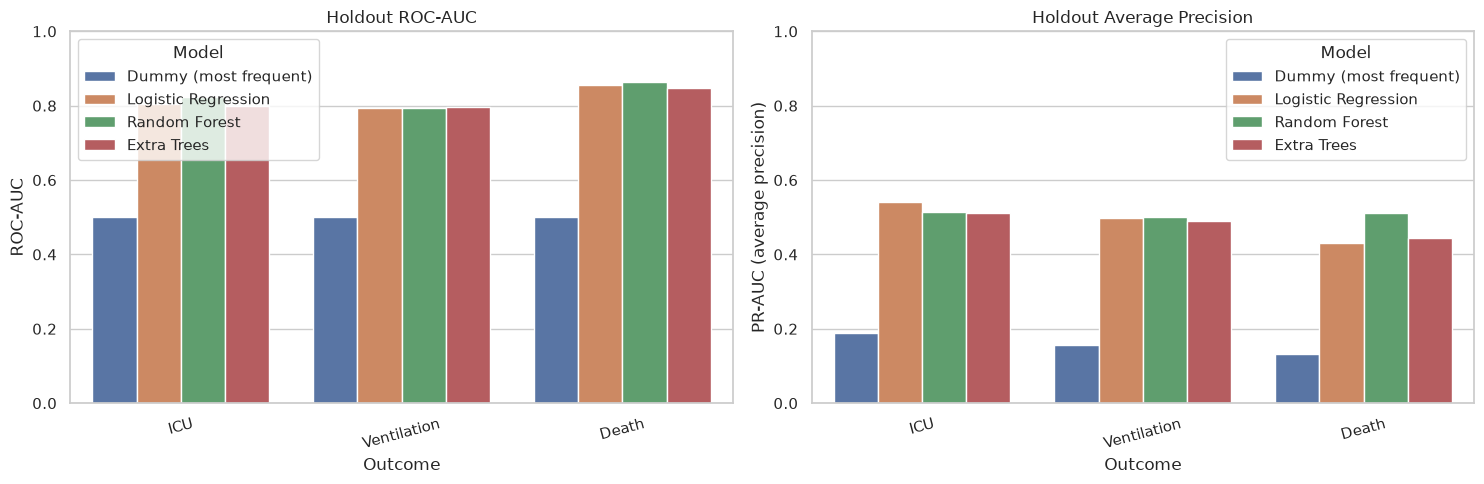

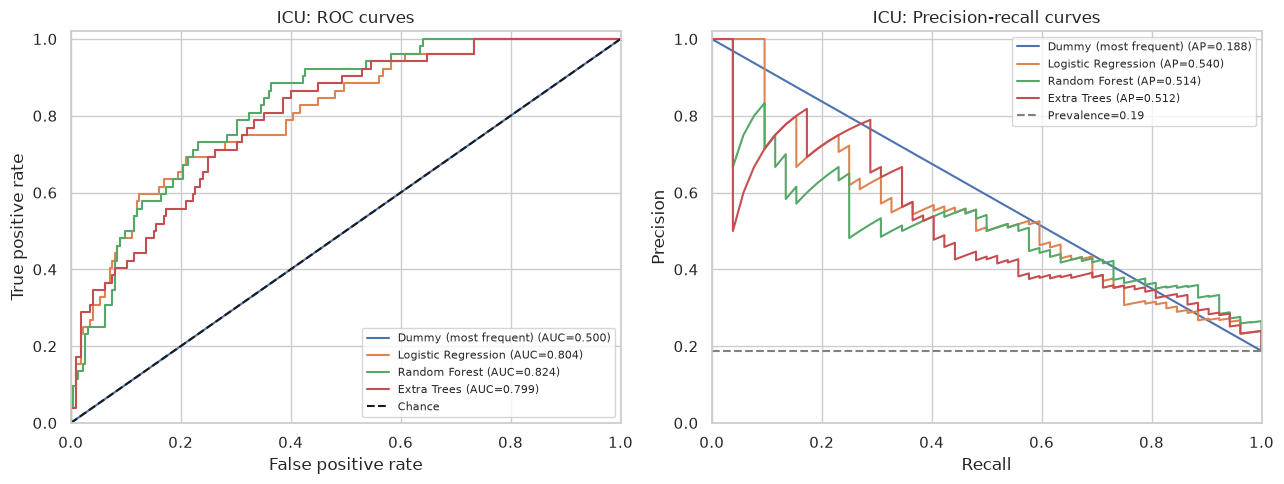

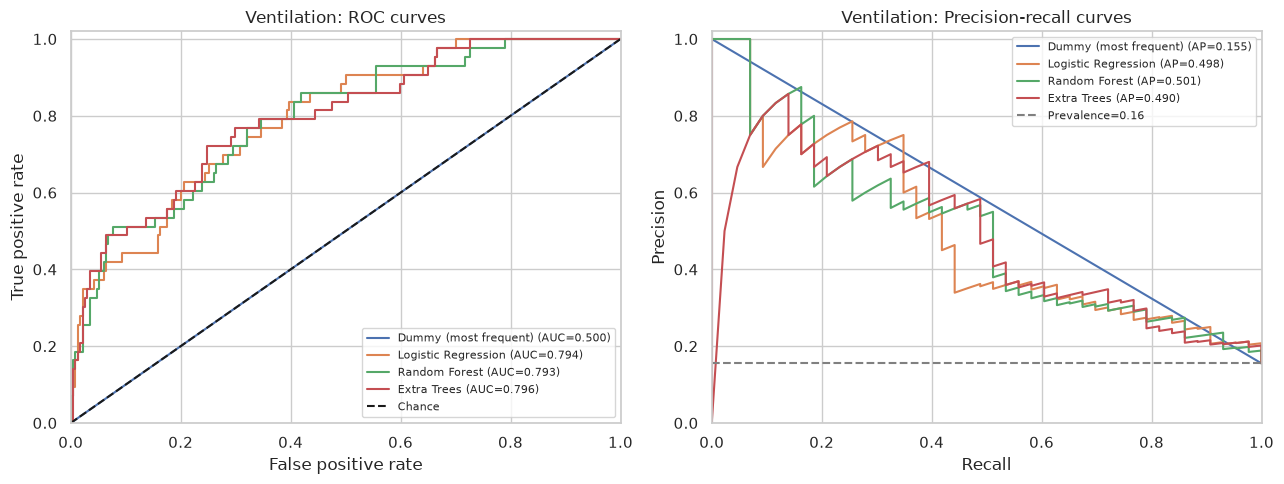

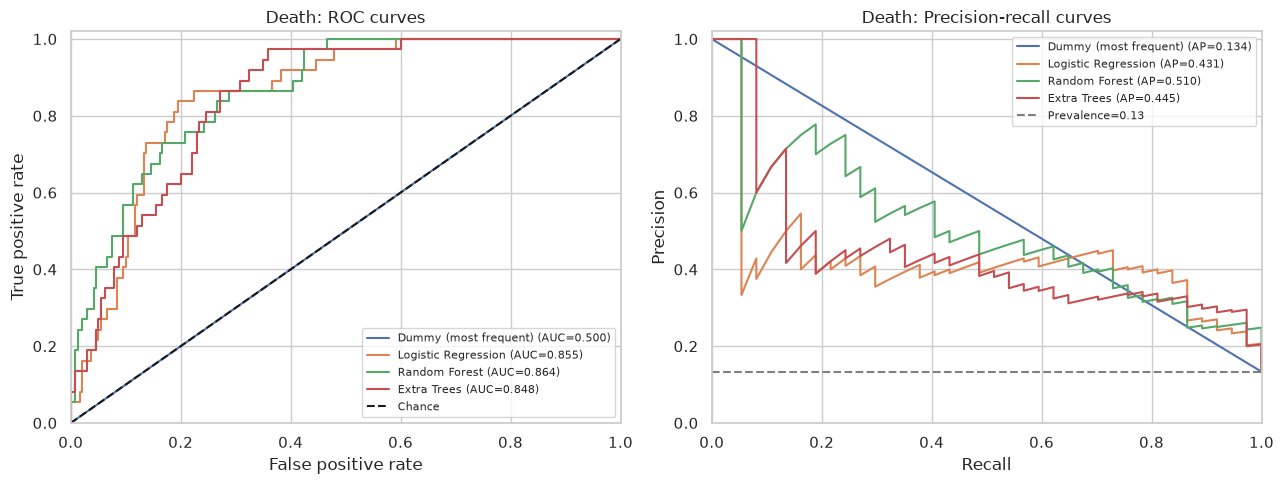

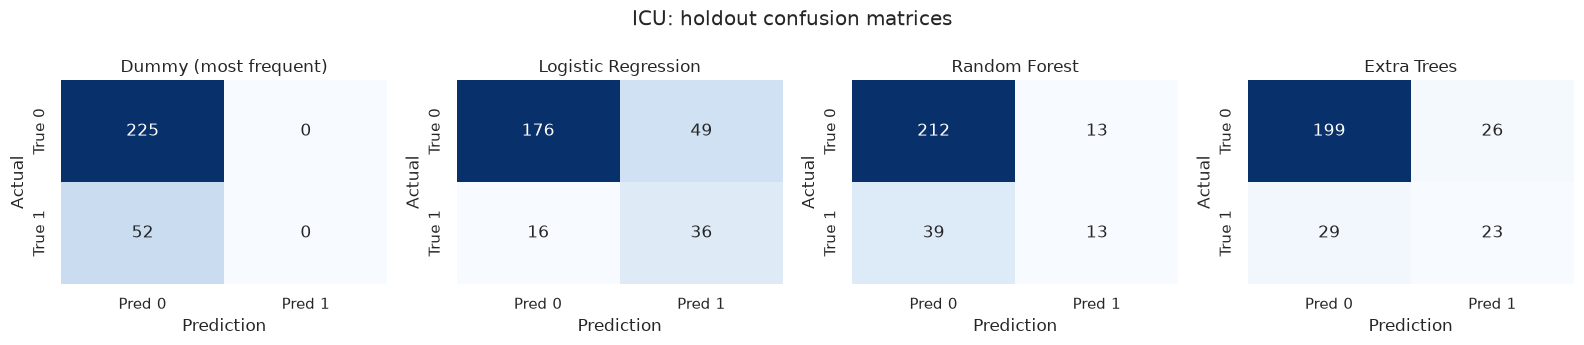

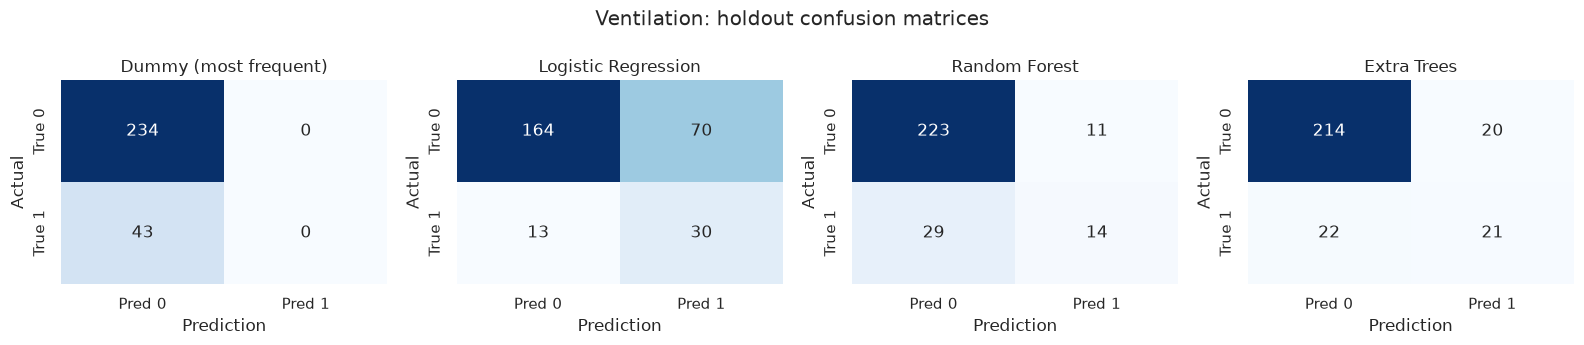

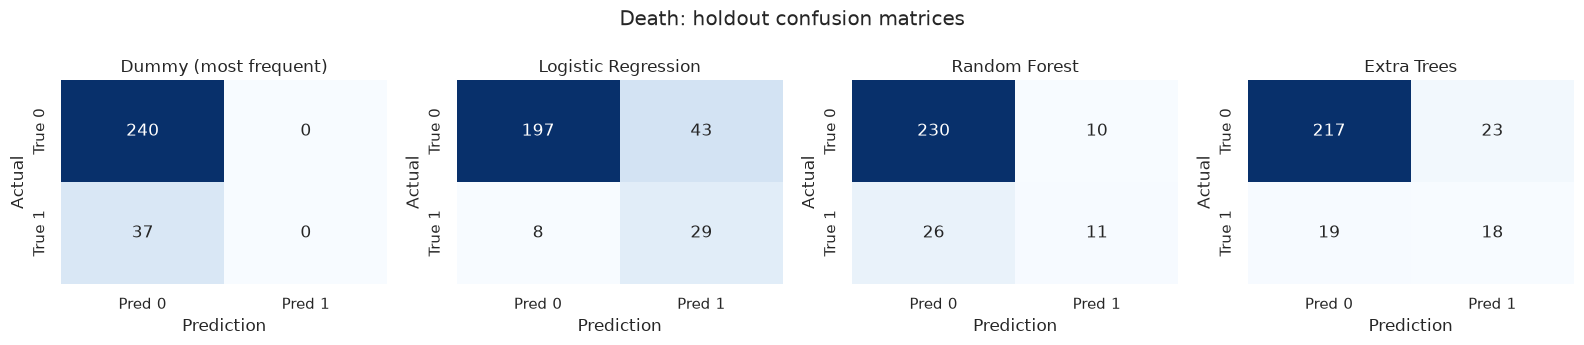

In [10]:
if holdout_df.empty:
    raise RuntimeError("No models were evaluated. Inspect label counts and data columns.")

# 8a. Holdout ROC-AUC and average precision comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=holdout_df, x="Outcome", y="ROC-AUC", hue="Model", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_title("Holdout ROC-AUC")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=holdout_df, x="Outcome", y="PR-AUC (average precision)", hue="Model", ax=axes[1])
axes[1].set_ylim(0, 1)
axes[1].set_title("Holdout Average Precision")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "model_auc_comparison.png"), dpi=220, bbox_inches="tight")
plt.show()

# 8b. ROC and PR curves for each outcome, with model-specific curves
for target in outcomes:
    target_models = [name for (out, name) in saved_predictions if out == target]
    if not target_models:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name in target_models:
        item = saved_predictions[(target, name)]
        fpr, tpr, _ = roc_curve(item["y_true"], item["y_prob"])
        precision, recall, _ = precision_recall_curve(item["y_true"], item["y_prob"])
        auc = roc_auc_score(item["y_true"], item["y_prob"])
        ap = average_precision_score(item["y_true"], item["y_prob"])
        axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
        axes[1].plot(recall, precision, label=f"{name} (AP={ap:.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
    prevalence = saved_predictions[(target, target_models[0])]["y_true"].mean()
    axes[1].axhline(prevalence, linestyle="--", color="gray", label=f"Prevalence={prevalence:.2f}")
    axes[0].set(title=f"{target}: ROC curves", xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
    axes[1].set(title=f"{target}: Precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f"{target.lower()}_roc_pr_curves.png"), dpi=220, bbox_inches="tight")
    plt.show()

# 8c. Confusion matrices for the final holdout predictions
for target in outcomes:
    target_models = [name for (out, name) in saved_predictions if out == target]
    if not target_models:
        continue
    fig, axes = plt.subplots(1, len(target_models), figsize=(4 * len(target_models), 3.5))
    if len(target_models) == 1:
        axes = [axes]
    for ax, name in zip(axes, target_models):
        item = saved_predictions[(target, name)]
        cm = confusion_matrix(item["y_true"], item["y_pred"], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], ax=ax)
        ax.set_title(name)
        ax.set_xlabel("Prediction")
        ax.set_ylabel("Actual")
    fig.suptitle(f"{target}: holdout confusion matrices")
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f"{target.lower()}_confusion_matrices.png"), dpi=220, bbox_inches="tight")
    plt.show()

## 9. Inspect false positives and false negatives

For the Logistic Regression model, inspect test-set errors without exposing patient IDs in exported artifacts. This can help explain the precision/recall trade-off, but it should not be used to make clinical decisions.

In [11]:
error_rows = []
for target in outcomes:
    key = (target, "Logistic Regression")
    if key not in saved_predictions:
        continue
    item = saved_predictions[key]
    y_true, y_pred, y_prob = item["y_true"], item["y_pred"], item["y_prob"]
    error_rows.append({
        "Outcome": target,
        "False positives": int(((y_true == 0) & (y_pred == 1)).sum()),
        "False negatives": int(((y_true == 1) & (y_pred == 0)).sum()),
        "True positives": int(((y_true == 1) & (y_pred == 1)).sum()),
        "True negatives": int(((y_true == 0) & (y_pred == 0)).sum()),
        "Median predicted score for positives": float(np.median(y_prob[y_true == 1])),
        "Median predicted score for negatives": float(np.median(y_prob[y_true == 0]))
    })
error_summary = pd.DataFrame(error_rows)
display(error_summary)
error_summary.to_csv(os.path.join(OUTPUT_DIR, "logistic_error_summary.csv"), index=False)

,Outcome,False positives,False negatives,True positives,True negatives,Median predicted score for positives,Median predicted score for negatives
0,ICU,49,16,36,176,0.622104,0.285294
1,Ventilation,70,13,30,164,0.652619,0.272045
2,Death,43,8,29,197,0.675050,0.141975
